# Homework 2

In [1]:
import copy
import matplotlib.pyplot as plt

# Assignments - Digital options

Create a new folder under <b>QuantCourseBP\homeworks</b> and copy over the content of this lecture's solution folder to start with.

1. Get familiar with digital options and implement EuropeanDigitalContract and EuropeanDigitalAnalyticPricer (fair value and greeks) in the library. Implement unit test for fair value using pytest. **(12 points)**
2. Get familiar with bull spread options and by utilizing EuropeanDigitalAnalyticPricer and EuropeanAnalyticPricer, create a figure to visualize that a digital call option can be thought of as a limit of bull spread call options. **(8 points)**

In [2]:
from src.enums import Stock
from src.market_data import MarketData
from src.model import FlatVolModel
from src.numerical_method import Params

MarketData.initialize()
model = FlatVolModel(Stock.BLUECHIP_BANK)
params = Params()

print("Spot:", model.spot)
print("Risk-free rate:", model.risk_free_rate)
print("Volatility:", model.get_vol(130.0, 1.0))

Spot: 130.17
Risk-free rate: 0.05
Volatility: 0.381


In [3]:
import numpy as np
from scipy.stats import norm
from src.enums import PutCallFwd, LongShort, Stock, GreekMethod
from src.contract import EuropeanDigitalContract
from src.pricer import EuropeanDigitalAnalyticPricer

contract = EuropeanDigitalContract(
    underlying=Stock.BLUECHIP_BANK,
    derivative_type=PutCallFwd.CALL,
    long_short=LongShort.LONG,
    strike=130.0,
    expiry=1.0,
)

digital_pricer = EuropeanDigitalAnalyticPricer(
    contract=contract,
    model=model,
    params=params,
)

calculated_price = digital_pricer.calc_fair_value()

S = model.spot
K = contract.strike
T = contract.expiry
r = model.risk_free_rate
sigma = model.get_vol(K, T)

d2 = (
    np.log(S / K) + (r - sigma**2 / 2) * T
) / (sigma * np.sqrt(T))

expected_price = np.exp(-r * T) * norm.cdf(d2)

print("Digital call price from pricer:", calculated_price)
print("Expected Black-Scholes price:   ", expected_price)
print("Prices match:", np.isclose(calculated_price, expected_price))

Digital call price from pricer: 0.4544366119642575
Expected Black-Scholes price:    0.4544366119642575
Prices match: True


In [4]:
contract = EuropeanDigitalContract(
    underlying=Stock.BLUECHIP_BANK,
    derivative_type=PutCallFwd.CALL,
    long_short=LongShort.LONG,
    strike=130.0,
    expiry=1.0,
)

pricer = EuropeanDigitalAnalyticPricer(contract, model, params)

print(f"Fair value: {pricer.calc_fair_value():.8f}")

greeks = {
    "Delta": pricer.calc_delta,
    "Gamma": pricer.calc_gamma,
    "Vega": pricer.calc_vega,
    "Theta": pricer.calc_theta,
    "Rho": pricer.calc_rho,
}

for name, calc in greeks.items():
    analytical = calc(GreekMethod.ANALYTIC)
    bumped = calc(GreekMethod.BUMP)
    print(
        f"{name:6s}: Analytic = {analytical:.8f}, "
        f"Bump = {bumped:.8f}"
    )

Fair value: 0.45443661
Delta : Analytic = 0.00763981, Bump = 0.00763913
Gamma : Analytic = -0.00005009, Bump = -0.00005007
Vega  : Analytic = -0.32336671, Bump = -0.32337978
Theta : Analytic = 0.03459950, Bump = 0.03461175
Rho   : Analytic = 0.54003723, Bump = 0.54003704


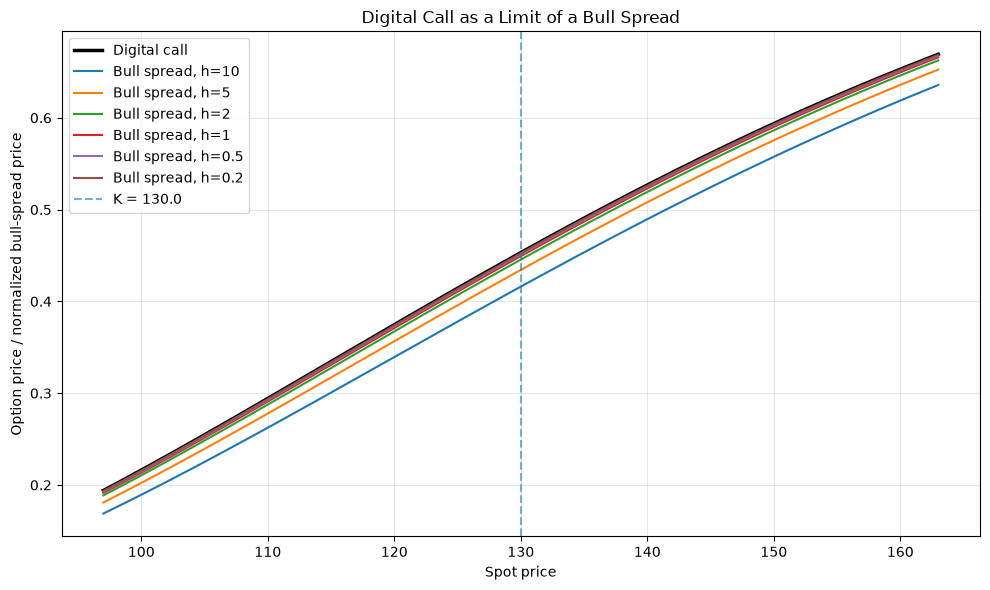

In [5]:
import copy
import numpy as np
import matplotlib.pyplot as plt

from src.contract import EuropeanContract, EuropeanDigitalContract
from src.enums import Stock, PutCallFwd, LongShort
from src.pricer import EuropeanAnalyticPricer, EuropeanDigitalAnalyticPricer
from src.market_data import LinearInterpolatorNearestExtrapolator

underlying = Stock.BLUECHIP_BANK
K = 130.0
T = 1.0
widths = [10.0, 5.0, 2.0, 1.0, 0.5, 0.2]

# Work on a copy, leaving your original model unchanged
plot_model = copy.deepcopy(model)

# Make the volatility grid constant for this illustration
volgrid = plot_model.volgrid
original_values = volgrid.values.copy()
constant_vol = model.get_vol(K, T)

try:
    volgrid.values[:] = constant_vol
    volgrid.interpolator = LinearInterpolatorNearestExtrapolator(
        volgrid.points, volgrid.values
    )

    spots = np.linspace(97.0, 163.0, 200)
    digital_prices = []
    spread_prices = {h: [] for h in widths}

    for S in spots:
        spot_model = copy.deepcopy(plot_model)
        spot_model.spot = S

        digital_contract = EuropeanDigitalContract(
            underlying=underlying,
            derivative_type=PutCallFwd.CALL,
            long_short=LongShort.LONG,
            strike=K,
            expiry=T,
        )
        digital_prices.append(
            EuropeanDigitalAnalyticPricer(
                digital_contract, spot_model, params
            ).calc_fair_value()
        )

        for h in widths:
            call_K = EuropeanContract(
                underlying=underlying,
                derivative_type=PutCallFwd.CALL,
                long_short=LongShort.LONG,
                strike=K,
                expiry=T,
            )
            call_Kh = EuropeanContract(
                underlying=underlying,
                derivative_type=PutCallFwd.CALL,
                long_short=LongShort.SHORT,
                strike=K + h,
                expiry=T,
            )

            c1 = EuropeanAnalyticPricer(
                call_K, spot_model, params
            ).calc_fair_value()
            c2 = EuropeanAnalyticPricer(
                call_Kh, spot_model, params
            ).calc_fair_value()

            spread_prices[h].append((c1 + c2) / h)

finally:
    # Restore the copy's original volatility grid
    volgrid.values[:] = original_values
    volgrid.interpolator = LinearInterpolatorNearestExtrapolator(
        volgrid.points, volgrid.values
    )

plt.figure(figsize=(10, 6))
plt.plot(spots, digital_prices, color="black", linewidth=2.5,
         label="Digital call")

for h in widths:
    plt.plot(spots, spread_prices[h], label=f"Bull spread, h={h:g}")

plt.axvline(K, linestyle="--", alpha=0.6, label=f"K = {K}")
plt.xlabel("Spot price")
plt.ylabel("Option price / normalized bull-spread price")
plt.title("Digital Call as a Limit of a Bull Spread")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()